# 1. Environment Setup
In this step, we import standard data science libraries (`pandas`, `matplotlib`, `seaborn`) and our custom-built backend package (`marketanalysis`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from marketanalysis.core import MarketAnalyzer
from marketanalysis.models import Stock

plt.style.use('ggplot')
%matplotlib inline

## 2. Data Acquisition & Processing
Here we initialize the `MarketAnalyzer` and define the scope of our analysis. We add representative stocks from the **Technology**, **Financial**, and **Healthcare** sectors. We then fetch historical data for the year 2023 and pre-calculate daily returns, which are required for the subsequent risk and correlation analyses.

In [ ]:
# 1. Initialize the Analyzer
analyzer = MarketAnalyzer(name="Sector Comparison: Tech vs. Finance vs. Healthcare")

# 2. Add Stocks
# We choose representative companies from different sectors to see distinct behaviors
print("Adding stocks to the analyzer...")

# Technology Sector (Growth, typically higher volatility)
analyzer.add_stock(Stock(ticker="AAPL", sector="Technology"))
analyzer.add_stock(Stock(ticker="MSFT", sector="Technology"))
analyzer.add_stock(Stock(ticker="NVDA", sector="Technology"))

# Financial Sector (Cyclical)
analyzer.add_stock(Stock(ticker="JPM", sector="Financials"))
analyzer.add_stock(Stock(ticker="BAC", sector="Financials"))

# Healthcare Sector (Defensive, typically lower volatility)
analyzer.add_stock(Stock(ticker="JNJ", sector="Healthcare"))
analyzer.add_stock(Stock(ticker="PFE", sector="Healthcare"))

# 3. Fetch Data
# We download data for the full year of 2023 to get a statistically significant sample
analyzer.fetch_data(start_date="2023-01-01", end_date="2023-12-31")

# 4. Calculate Daily Returns
# This is a prerequisite for volatility and correlation analysis
analyzer.calculate_daily_returns()

Adding stocks to the analyzer...


C:\Users\Victor\VSCProjects\PythonProjects\CodingDSE\market_pulse_project\marketanalysis\core.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  all_data = yf.download(
[*********************100%***********************]  7 of 7 completed

Data processing complete.


## 3. Volatility Analysis (Risk Assessment)
This section addresses the project requirement to **investigate which sectors are most volatile**. We calculate the standard deviation of daily returns for each stock and visualize it using a bar chart. Higher bars indicate higher instability (risk).

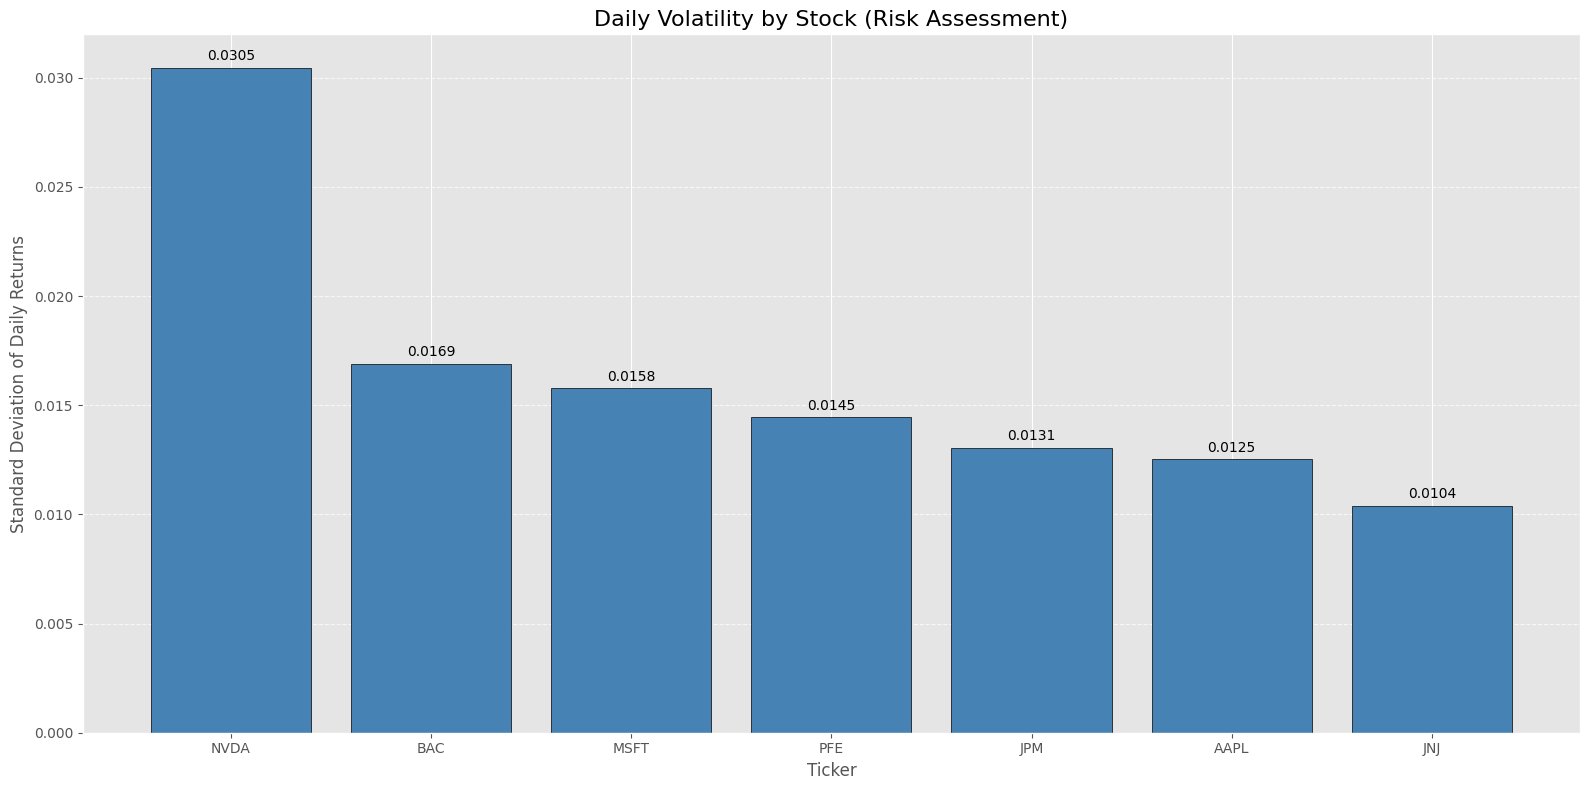

In [ ]:
# 1. Calculate Volatility
volatility_series = analyzer.calculate_volatility()

if volatility_series is not None:
    # Sort data for a better visualization (highest risk on the left)
    vol_sorted = volatility_series.sort_values(ascending=False)

    # 2. Create the Plot 
    fig, ax = plt.subplots(figsize=(16, 8))

    # Create a bar chart
    bars = ax.bar(vol_sorted.index, vol_sorted.values, color='steelblue', edgecolor='black')

    # 3. Customize the Plot
    ax.set_title("Daily Volatility by Stock (Risk Assessment)", fontsize=16)
    ax.set_ylabel("Standard Deviation of Daily Returns")
    ax.set_xlabel("Ticker")
    
    # Add gridlines for readability
    ax.yaxis.grid(True, linestyle='--', alpha=0.7)

    # Add labels on top of bars
    ax.bar_label(bars, fmt='%.4f', padding=3)

    plt.tight_layout()
    plt.show()
else:
    print("No volatility data available to plot.")

## 4. Correlation Analysis
Here we generate a **Correlation Matrix** to understand how the stocks interact with each other. We visualize this using a **Seaborn Heatmap**.
* **Red (towards 1.0):** Stocks move in the same direction.
* **Blue (towards -1.0):** Stocks move in opposite directions.

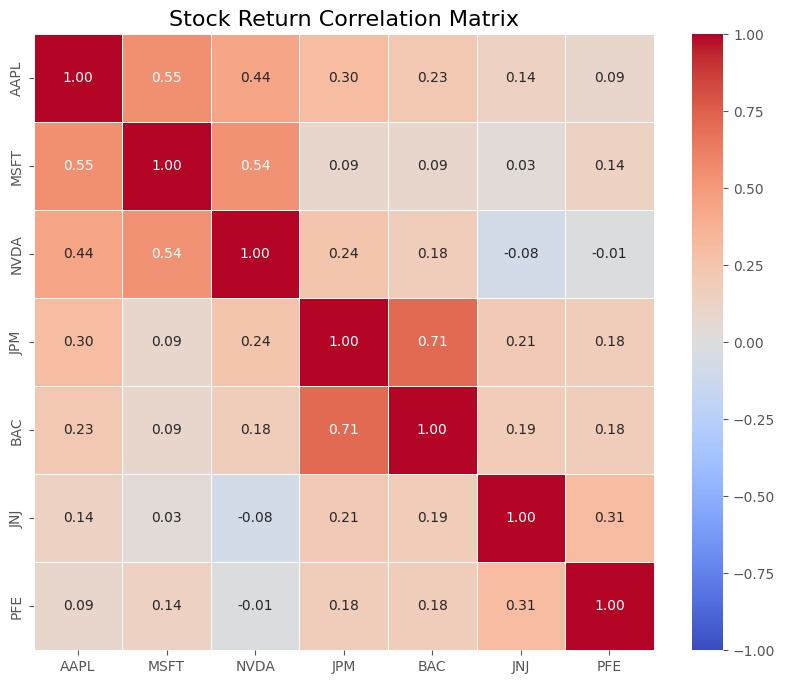

In [4]:
# 1. Calculate Correlation Matrix
corr_matrix = analyzer.get_correlation_matrix()

if corr_matrix is not None:
    # 2. Create the Figure
    plt.figure(figsize=(10, 8))

    # 3. Create Heatmap using Seaborn
    # annot=True: Write the data value in each cell
    # cmap='coolwarm': Blue for negative correlation, Red for positive
    # vmin=-1, vmax=1: Set the scale limits
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)

    plt.title("Stock Return Correlation Matrix", fontsize=16)
    plt.show()
else:
    print("No correlation matrix available to plot.")

## 5. Relative Price Performance
To provide context, we visualize the price evolution of these stocks. We normalize the prices to a **"Base 100"** at the start of the period. This allows us to compare the cumulative performance of stocks with vastly different share prices (e.g., comparing a \$150 stock vs. a \$40 stock).

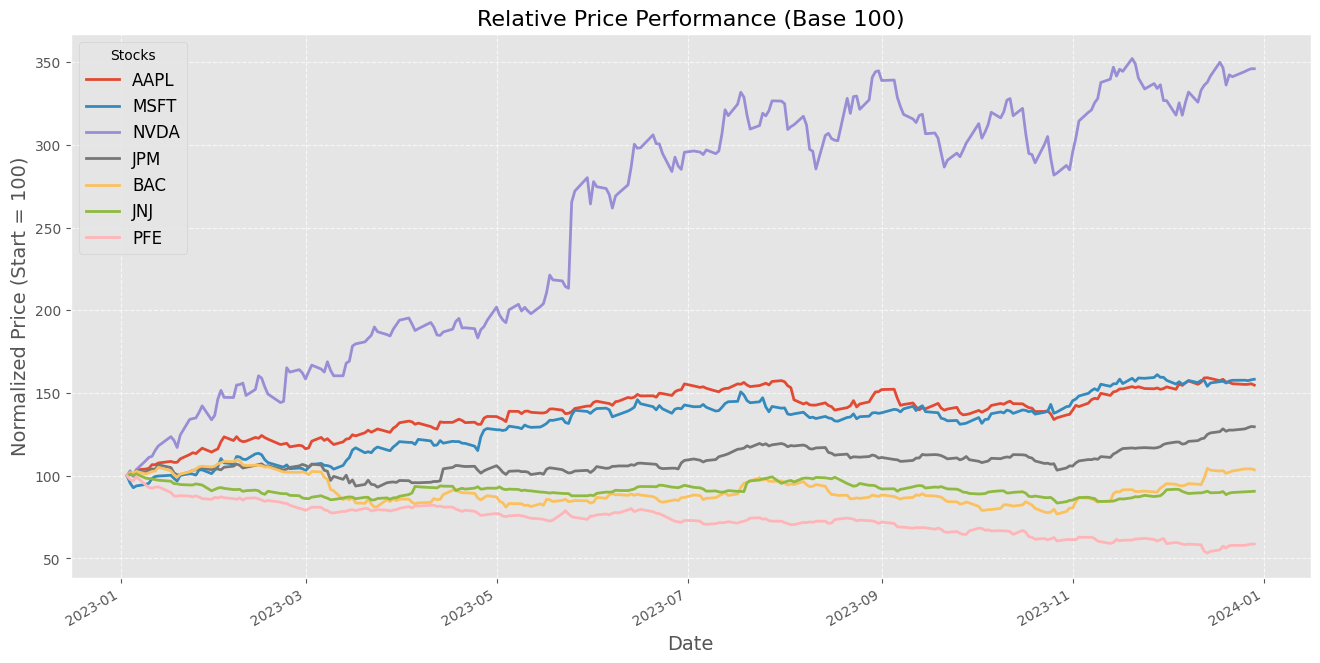

In [20]:
# Create a DataFrame to hold normalized prices
normalized_prices = pd.DataFrame()

for stock in analyzer.stocks:
    if not stock.data.empty:
        # Normalize prices to start at 100 (Base 100)
        # This allows us to compare relative performance regardless of share price
        first_price = stock.data['Close'].iloc[0]
        normalized_prices[stock.ticker] = (stock.data['Close'] / first_price) * 100

if not normalized_prices.empty:
    fig, ax = plt.subplots(figsize=(16, 8))
    
    normalized_prices.plot(ax=ax, linewidth=2)
    
    ax.set_title("Relative Price Performance (Base 100)", fontsize=16)
    ax.set_ylabel("Normalized Price (Start = 100)", fontsize=14)
    ax.set_xlabel("Date", fontsize=14)
    ax.legend(title="Stocks", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.7)
    
    plt.show()
else:
    print("No price data available.")